# Analisis Akurasi Persona Regional-Kultural pada GSM8K - Enam Model Utama

Notebook ini adalah lapisan presentasi read-only untuk tiga visual akurasi
Regional-Kultural yang dirujuk Bab VI: akurasi absolut, delta Implicit-Explicit,
dan heatmap ukuran efek Cohen's h dengan keputusan Holm.

Sumber statistik tetap bundle v5 yang tervalidasi. Notebook tidak memanggil API,
tidak melakukan parsing/scoring ulang, dan tidak menghitung ulang uji statistik.

## 1. SPEC dan provenance

- Full GSM8K test split: 1.319 soal.
- 6 model x 16 kondisi persona Regional (empat region, masing-masing E dan I1-I3).
- Neutral pada Figure 12 hanya baseline visual deskriptif yang dipinjam dari
  tabel Neutral Gender untuk model yang sama; sumber Regional tidak menyediakan
  pasangan Neutral dengan protokol inferensi yang sama.
- Perbandingan utama I1-I3 terhadap E tetap dibaca dari 72 pasangan tingkat soal,
  Exact McNemar, Cochran's Q, dan koreksi Holm yang sudah tersimpan.

In [1]:
from __future__ import annotations

import hashlib
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 400)

EXPECTED_FIGURE_HASHES = {
  "12_regional_absolute_accuracy_explicit_implicit.png": "1962d584b9c10c1127ccbdf5d2ea9845a41f3b4f2e4feb384ea5346fcc468bd8",
  "12_regional_absolute_accuracy_explicit_implicit.svg": "c11beb6c120835b154cb51783577d5a643dfbf29e024175a9397eb0e38c5b435",
  "13_regional_delta_implicit_vs_explicit.png": "86e0e2ad092ea529a13c7999681bd233ae120875c8e76950d2246976770fc214",
  "13_regional_delta_implicit_vs_explicit.svg": "4fac665b61a96a95e9b7b92556e05ef9b86b522696cac54afdeb3979c65d6c98",
  "27_regional_all_52_effect_holm_stacked_26_26.png": "62609f9c5bdd47c325d7615e620e2c39e98424c563e546e2577aa2dd397932c3",
  "27_regional_all_52_effect_holm_stacked_26_26.svg": "ee43bd7c1225786659b11cddc0473ab8c7942251b0c92c056c53ac7d82dcdf3b"
}
EXPECTED_TABLE_HASHES = {
  "accuracy_by_persona_six_models.csv": "692fbdb0502922c2d39a1e3c538e83126d749e9619b891920de9d64e2c44c1bb",
  "regional_accuracy_and_deltas.csv": "020320ede59d6357b0a9e36c61f9722ff2df7ba887becd48a1b1931a12e934e8",
  "regional_paired_effects_significance.csv": "45135b29d095a300c1d86c886c4640f4b745d2856cd3c1ab200545b844c5c272",
  "regional_all_52_paired_effects_significance.csv": "f6e777e3f49d5335f08532edb56e59dec3f35b318b1d01432a130ce956fe9c6a",
  "cochran_q_omnibus_all_groups.csv": "b78eebbf2e51dfef4770f0ddd6d0be947d8fae3f072af1ff12062fc1350182a5",
  "regional_completion_token_delta_implicit_vs_explicit.csv": "2b16332b267044bcf7582cf7ff1d6b5cd3d38387e43131aaf275109287f5b890",
  "neutral_persona_accuracy_six_models.csv": "bd10ef481280a6f46a26d1ce2845e875837a0513da36f87246722fac09bd57b8"
}

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def find_repo_root() -> Path:
    for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (path / 'result' / 'GMS8K').is_dir() and (path / 'notebooks').is_dir():
            return path
    raise FileNotFoundError('Jalankan dari D:/TugasAkhir atau subfoldernya.')

REPO_ROOT = find_repo_root()
TABLE_DIR = REPO_ROOT / 'result' / 'GMS8K' / 'reports' / 'persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold' / 'tables'
FIGURE_DIR = REPO_ROOT / 'notebooks' / 'regional' / 'akurasi analysis' / 'figures'
print('Tabel v5 read-only:', TABLE_DIR)
print('Gambar lokal:', FIGURE_DIR)

Tabel v5 read-only: D:\TugasAkhir\result\GMS8K\reports\persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold\tables
Gambar lokal: D:\TugasAkhir\notebooks\regional\akurasi analysis\figures


## 2. Validation gate

In [2]:
accuracy_all = pd.read_csv(TABLE_DIR / 'accuracy_by_persona_six_models.csv', low_memory=False)
regional_accuracy = accuracy_all[accuracy_all['dataset'].eq('Regional Cultural')].copy()
regional_summary = pd.read_csv(TABLE_DIR / 'regional_accuracy_and_deltas.csv')
regional_pairs = pd.read_csv(TABLE_DIR / 'regional_paired_effects_significance.csv', low_memory=False)
regional_all = pd.read_csv(TABLE_DIR / 'regional_all_52_paired_effects_significance.csv', low_memory=False)
omnibus = pd.read_csv(TABLE_DIR / 'cochran_q_omnibus_all_groups.csv', low_memory=False)
regional_omnibus = omnibus[omnibus['dataset'].eq('Regional Cultural')].copy()

for name, expected in EXPECTED_TABLE_HASHES.items():
    assert sha256_file(TABLE_DIR / name) == expected, name
for name, expected in EXPECTED_FIGURE_HASHES.items():
    path = FIGURE_DIR / name
    assert path.is_file() and path.stat().st_size > 0, path
    assert sha256_file(path) == expected, path

validation = pd.DataFrame([
    ('Model', regional_accuracy['model'].nunique() == 6, regional_accuracy['model'].nunique()),
    ('Persona Regional', regional_accuracy['persona'].nunique() == 16, regional_accuracy['persona'].nunique()),
    ('Baris akurasi Regional', len(regional_accuracy) == 96, len(regional_accuracy)),
    ('Full test split', regional_accuracy['raw_total'].eq(1319).all(), sorted(regional_accuracy['raw_total'].unique().tolist())),
    ("Cochran's Q Regional", len(regional_omnibus) == 24, len(regional_omnibus)),
    ('Perbandingan I-E utama', len(regional_pairs) == 72, len(regional_pairs)),
    ('Seluruh 52 perbandingan', len(regional_all) == 312, len(regional_all)),
    ('Ringkasan visual', len(regional_summary) == 6, len(regional_summary)),
    ('Hash tabel v5', True, len(EXPECTED_TABLE_HASHES)),
    ('Hash PNG/SVG lokal', True, len(EXPECTED_FIGURE_HASHES)),
], columns=['gate', 'passed', 'observed'])
assert validation['passed'].all()
display(validation)
print('SEMUA VALIDATION GATE LULUS')

,gate,passed,observed
0,Model,True,6
1,Persona Regional,True,16
2,Baris akurasi Regional,True,96
3,Full test split,True,[1319]
4,Cochran's Q Regional,True,24
5,Perbandingan I-E utama,True,72
6,Seluruh 52 perbandingan,True,312
7,Ringkasan visual,True,6
8,Hash tabel v5,True,7
9,Hash PNG/SVG lokal,True,6


SEMUA VALIDATION GATE LULUS


## 3. Tabel akurasi dan coverage seluruh kondisi

In [3]:
columns = ['model_label', 'persona', 'raw_total', 'correct', 'total', 'accuracy_pct',
           'committed', 'commit_rate_pct', 'abstain', 'missing', 'technical_failures',
           'accuracy_committed_pct']
display(regional_accuracy[columns].sort_values(['model_label', 'persona']).reset_index(drop=True).style.format({
    'accuracy_pct': '{:.4f}%', 'commit_rate_pct': '{:.4f}%',
    'accuracy_committed_pct': '{:.4f}%'}))

display(Markdown('### Ringkasan yang dipakai untuk Figure 12 dan 13'))
display(regional_summary.style.format(precision=4))

,model_label,persona,raw_total,correct,total,accuracy_pct,committed,commit_rate_pct,abstain,missing,technical_failures,accuracy_committed_pct
0,DeepSeek R1-Distill 32B,east_asian_explicit,1319,1248,1319,94.6171%,1319,100.0000%,0,0,0,94.6171%
1,DeepSeek R1-Distill 32B,east_asian_implicit_1,1319,1237,1319,93.7832%,1317,99.8484%,2,0,0,93.9256%
2,DeepSeek R1-Distill 32B,east_asian_implicit_2,1319,1238,1319,93.8590%,1312,99.4693%,7,0,0,94.3598%
3,DeepSeek R1-Distill 32B,east_asian_implicit_3,1319,1250,1319,94.7688%,1313,99.5451%,6,0,0,95.2018%
4,DeepSeek R1-Distill 32B,north_american_explicit,1319,1248,1319,94.6171%,1319,100.0000%,0,0,0,94.6171%
5,DeepSeek R1-Distill 32B,north_american_implicit_1,1319,1228,1319,93.1008%,1311,99.3935%,8,0,0,93.6690%
6,DeepSeek R1-Distill 32B,north_american_implicit_2,1319,1233,1319,93.4799%,1314,99.6209%,5,0,0,93.8356%
7,DeepSeek R1-Distill 32B,north_american_implicit_3,1319,1221,1319,92.5701%,1315,99.6967%,4,0,0,92.8517%
8,DeepSeek R1-Distill 32B,south_asian_explicit,1319,1253,1319,94.9962%,1319,100.0000%,0,0,0,94.9962%
9,DeepSeek R1-Distill 32B,south_asian_implicit_1,1319,1234,1319,93.5557%,1313,99.5451%,6,0,0,93.9832%


### Ringkasan yang dipakai untuk Figure 12 dan 13

,model,model_label,Neutral,North American Explicit,North American Implicit Avg,North American Delta Imp-Exp,East Asian Explicit,East Asian Implicit Avg,East Asian Delta Imp-Exp,South Asian Explicit,South Asian Implicit Avg,South Asian Delta Imp-Exp,Sub-Saharan African Explicit,Sub-Saharan African Implicit Avg,Sub-Saharan African Delta Imp-Exp
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,94.0819,96.5883,95.3753,-1.2130,95.9060,95.5752,-0.3308,96.4367,95.1226,-1.3141,96.5125,95.3489,-1.1636
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,84.3063,82.6384,81.9308,-0.7076,83.2449,81.6022,-1.6427,83.6998,82.7394,-0.9603,82.6384,80.6672,-1.9712
2,mistralai_ministral-8b-2512,Ministral 8B,93.4750,91.9636,91.8625,-0.1011,91.0538,91.1044,0.0505,89.6892,90.6242,0.9351,91.3571,90.0430,-1.3141
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,93.9300,94.6171,93.0503,-1.5668,94.6171,94.1370,-0.4802,94.9962,93.9601,-1.0361,94.5413,93.5305,-1.0109
4,openai_gpt-oss-20b,GPT-OSS 20B,93.9302,92.0213,91.5280,-0.4933,92.9385,92.4633,-0.4752,91.7933,91.8774,0.0841,92.1152,91.8857,-0.2296
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,91.9575,92.2669,92.6207,0.3538,93.2525,92.4438,-0.8087,94.1622,92.8734,-1.2889,92.9492,92.5954,-0.3538


## 4. Visual akurasi dan delta Regional-Kultural

### `12_regional_absolute_accuracy_explicit_implicit.png`

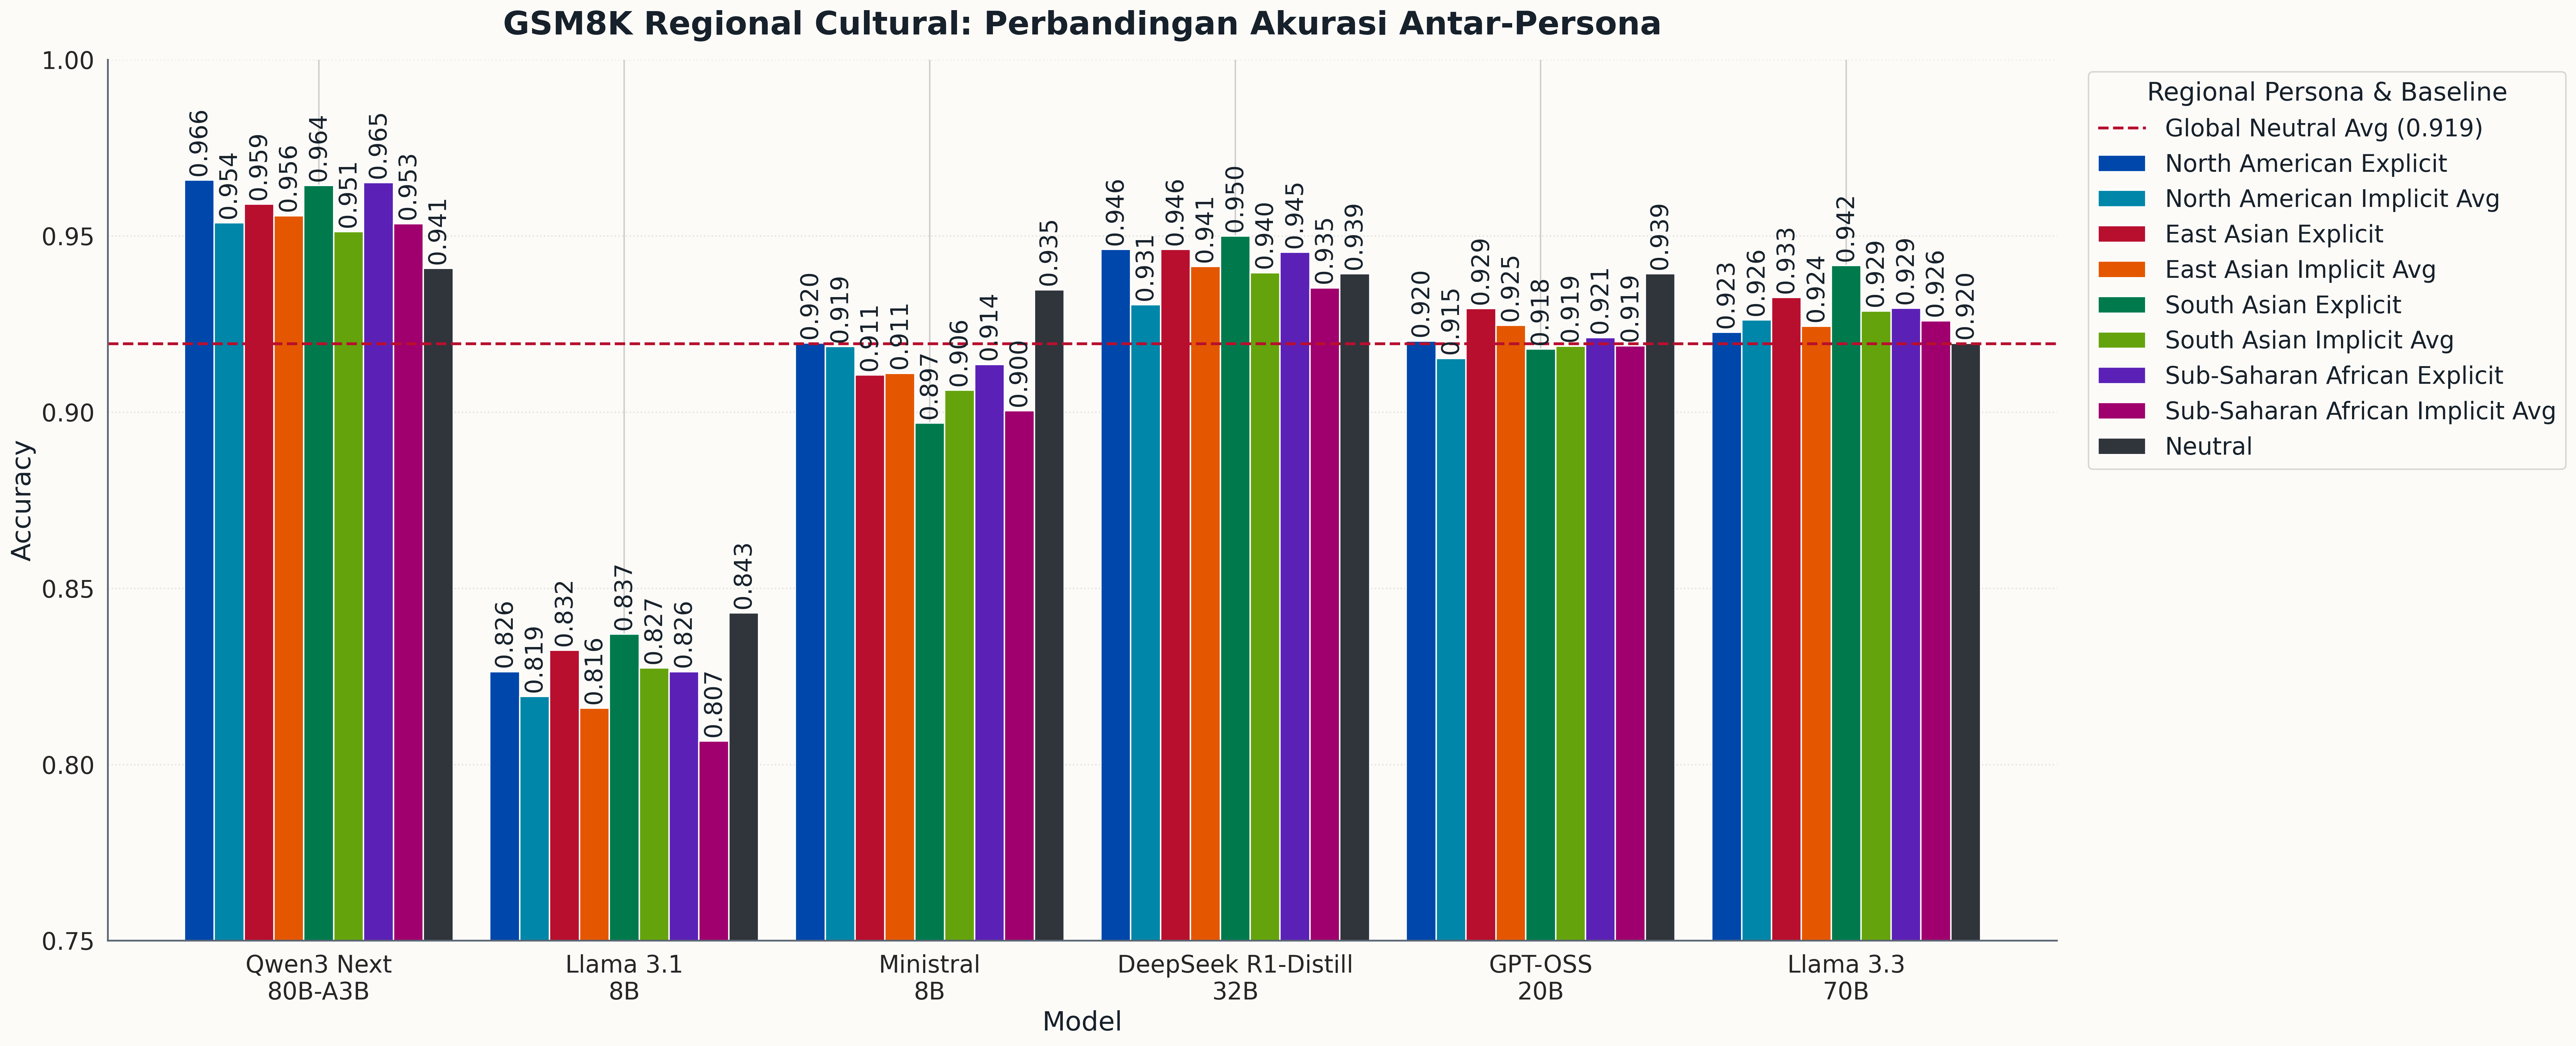

### `13_regional_delta_implicit_vs_explicit.png`

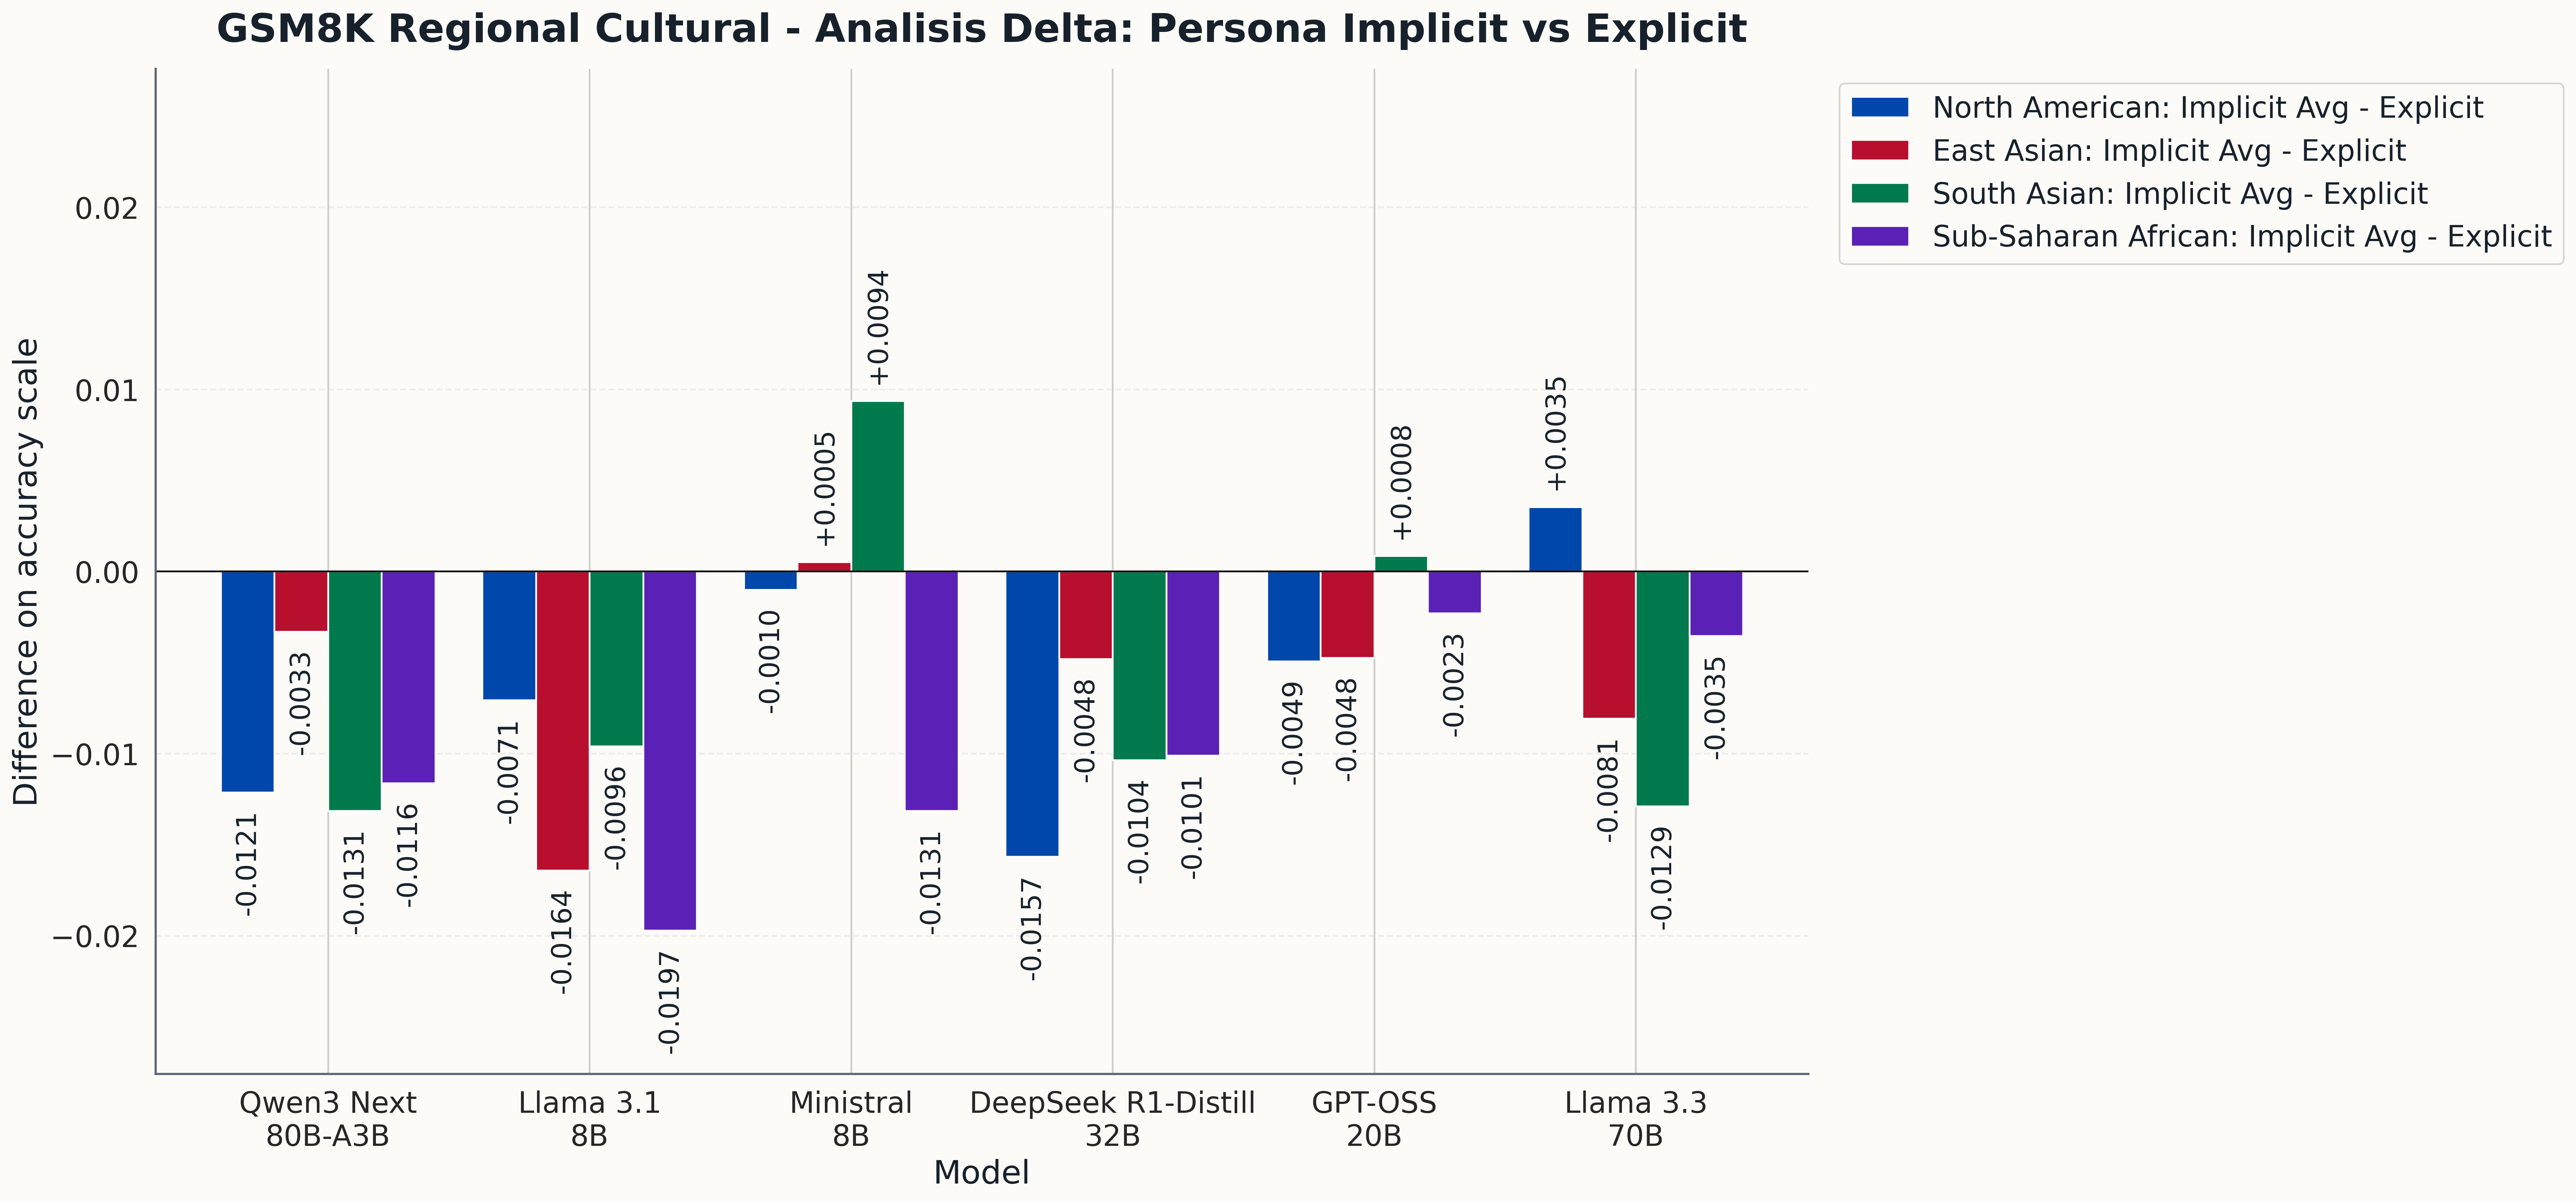

In [4]:
def show_figure(name: str, width: int) -> None:
    display(Markdown(f'### `{name}`'))
    display(Image(filename=str(FIGURE_DIR / name), width=width))

show_figure('12_regional_absolute_accuracy_explicit_implicit.png', 1550)
show_figure('13_regional_delta_implicit_vs_explicit.png', 1500)

## 5. Exact McNemar, Cochran's Q, Cohen's h, dan Holm

Figure 27 berisi 52 perbandingan per model: sensitivitas terhadap Neutral,
perbandingan Implicit-Explicit, dan perbandingan lintas region. Tanda bintang
dan cetak tebal pada sel hanya berasal dari `significant_holm_0_05`; arti tanda
lainnya mengikuti caption Bab VI. Neutral pada bagian sensitivitas adalah
protokol deskriptif yang berbeda, bukan uji Regional-vs-Neutral utama.

,model_label,family,family_size,comparisons,holm_significant
0,DeepSeek R1-Distill 32B,east_asian_neutral_sensitivity_four,4,4,0
1,DeepSeek R1-Distill 32B,east_asian_primary_three,3,3,0
2,DeepSeek R1-Distill 32B,north_american_neutral_sensitivity_four,4,4,0
3,DeepSeek R1-Distill 32B,north_american_primary_three,3,3,1
4,DeepSeek R1-Distill 32B,regional_cross_identity_twenty_four,24,24,1
5,DeepSeek R1-Distill 32B,south_asian_neutral_sensitivity_four,4,4,0
6,DeepSeek R1-Distill 32B,south_asian_primary_three,3,3,0
7,DeepSeek R1-Distill 32B,sub_saharan_african_neutral_sensitivity_four,4,4,0
8,DeepSeek R1-Distill 32B,sub_saharan_african_primary_three,3,3,0
9,GPT-OSS 20B,east_asian_neutral_sensitivity_four,4,4,0


,model_label,identity,analysis_scope,family,family_size,comparison_label,n_pairs,accuracy_a_pct,accuracy_b_pct,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,significant_holm_0_05,decision_significant_0_05,supports_primary_claim
0,DeepSeek R1-Distill 32B,east_asian,primary,east_asian_primary_three,3,East Asian Implicit 1 - East Asian Explicit,1319,93.783169,94.617134,-0.833965,-0.035701,0.266412,0.799237,False,False,False
1,DeepSeek R1-Distill 32B,east_asian,primary,east_asian_primary_three,3,East Asian Implicit 2 - East Asian Explicit,1319,93.858984,94.617134,-0.758150,-0.032552,0.314307,0.799237,False,False,False
2,DeepSeek R1-Distill 32B,east_asian,primary,east_asian_primary_three,3,East Asian Implicit 3 - East Asian Explicit,1319,94.768764,94.617134,0.151630,0.006764,0.907561,0.907561,False,False,False
3,DeepSeek R1-Distill 32B,north_american,primary,north_american_primary_three,3,North American Implicit 1 - North American Exp...,1319,93.100834,94.617134,-1.516300,-0.063274,0.035241,0.070483,False,False,False
4,DeepSeek R1-Distill 32B,north_american,primary,north_american_primary_three,3,North American Implicit 2 - North American Exp...,1319,93.479909,94.617134,-1.137225,-0.048121,0.123853,0.123853,False,False,False
5,DeepSeek R1-Distill 32B,north_american,primary,north_american_primary_three,3,North American Implicit 3 - North American Exp...,1319,92.570129,94.617134,-2.047005,-0.083856,0.005545,0.016635,True,True,True
6,DeepSeek R1-Distill 32B,south_asian,primary,south_asian_primary_three,3,South Asian Implicit 1 - South Asian Explicit,1319,93.555724,94.996209,-1.440485,-0.062128,0.027120,0.081360,False,False,False
7,DeepSeek R1-Distill 32B,south_asian,primary,south_asian_primary_three,3,South Asian Implicit 2 - South Asian Explicit,1319,93.858984,94.996209,-1.137225,-0.049639,0.114660,0.229321,False,False,False
8,DeepSeek R1-Distill 32B,south_asian,primary,south_asian_primary_three,3,South Asian Implicit 3 - South Asian Explicit,1319,94.465504,94.996209,-0.530705,-0.023761,0.482789,0.482789,False,False,False
9,DeepSeek R1-Distill 32B,sub_saharan_african,primary,sub_saharan_african_primary_three,3,Sub-Saharan African Implicit 1 - Sub-Saharan A...,1319,93.404094,94.541319,-1.137225,-0.047836,0.137368,0.274736,False,False,False


### `27_regional_all_52_effect_holm_stacked_26_26.png`

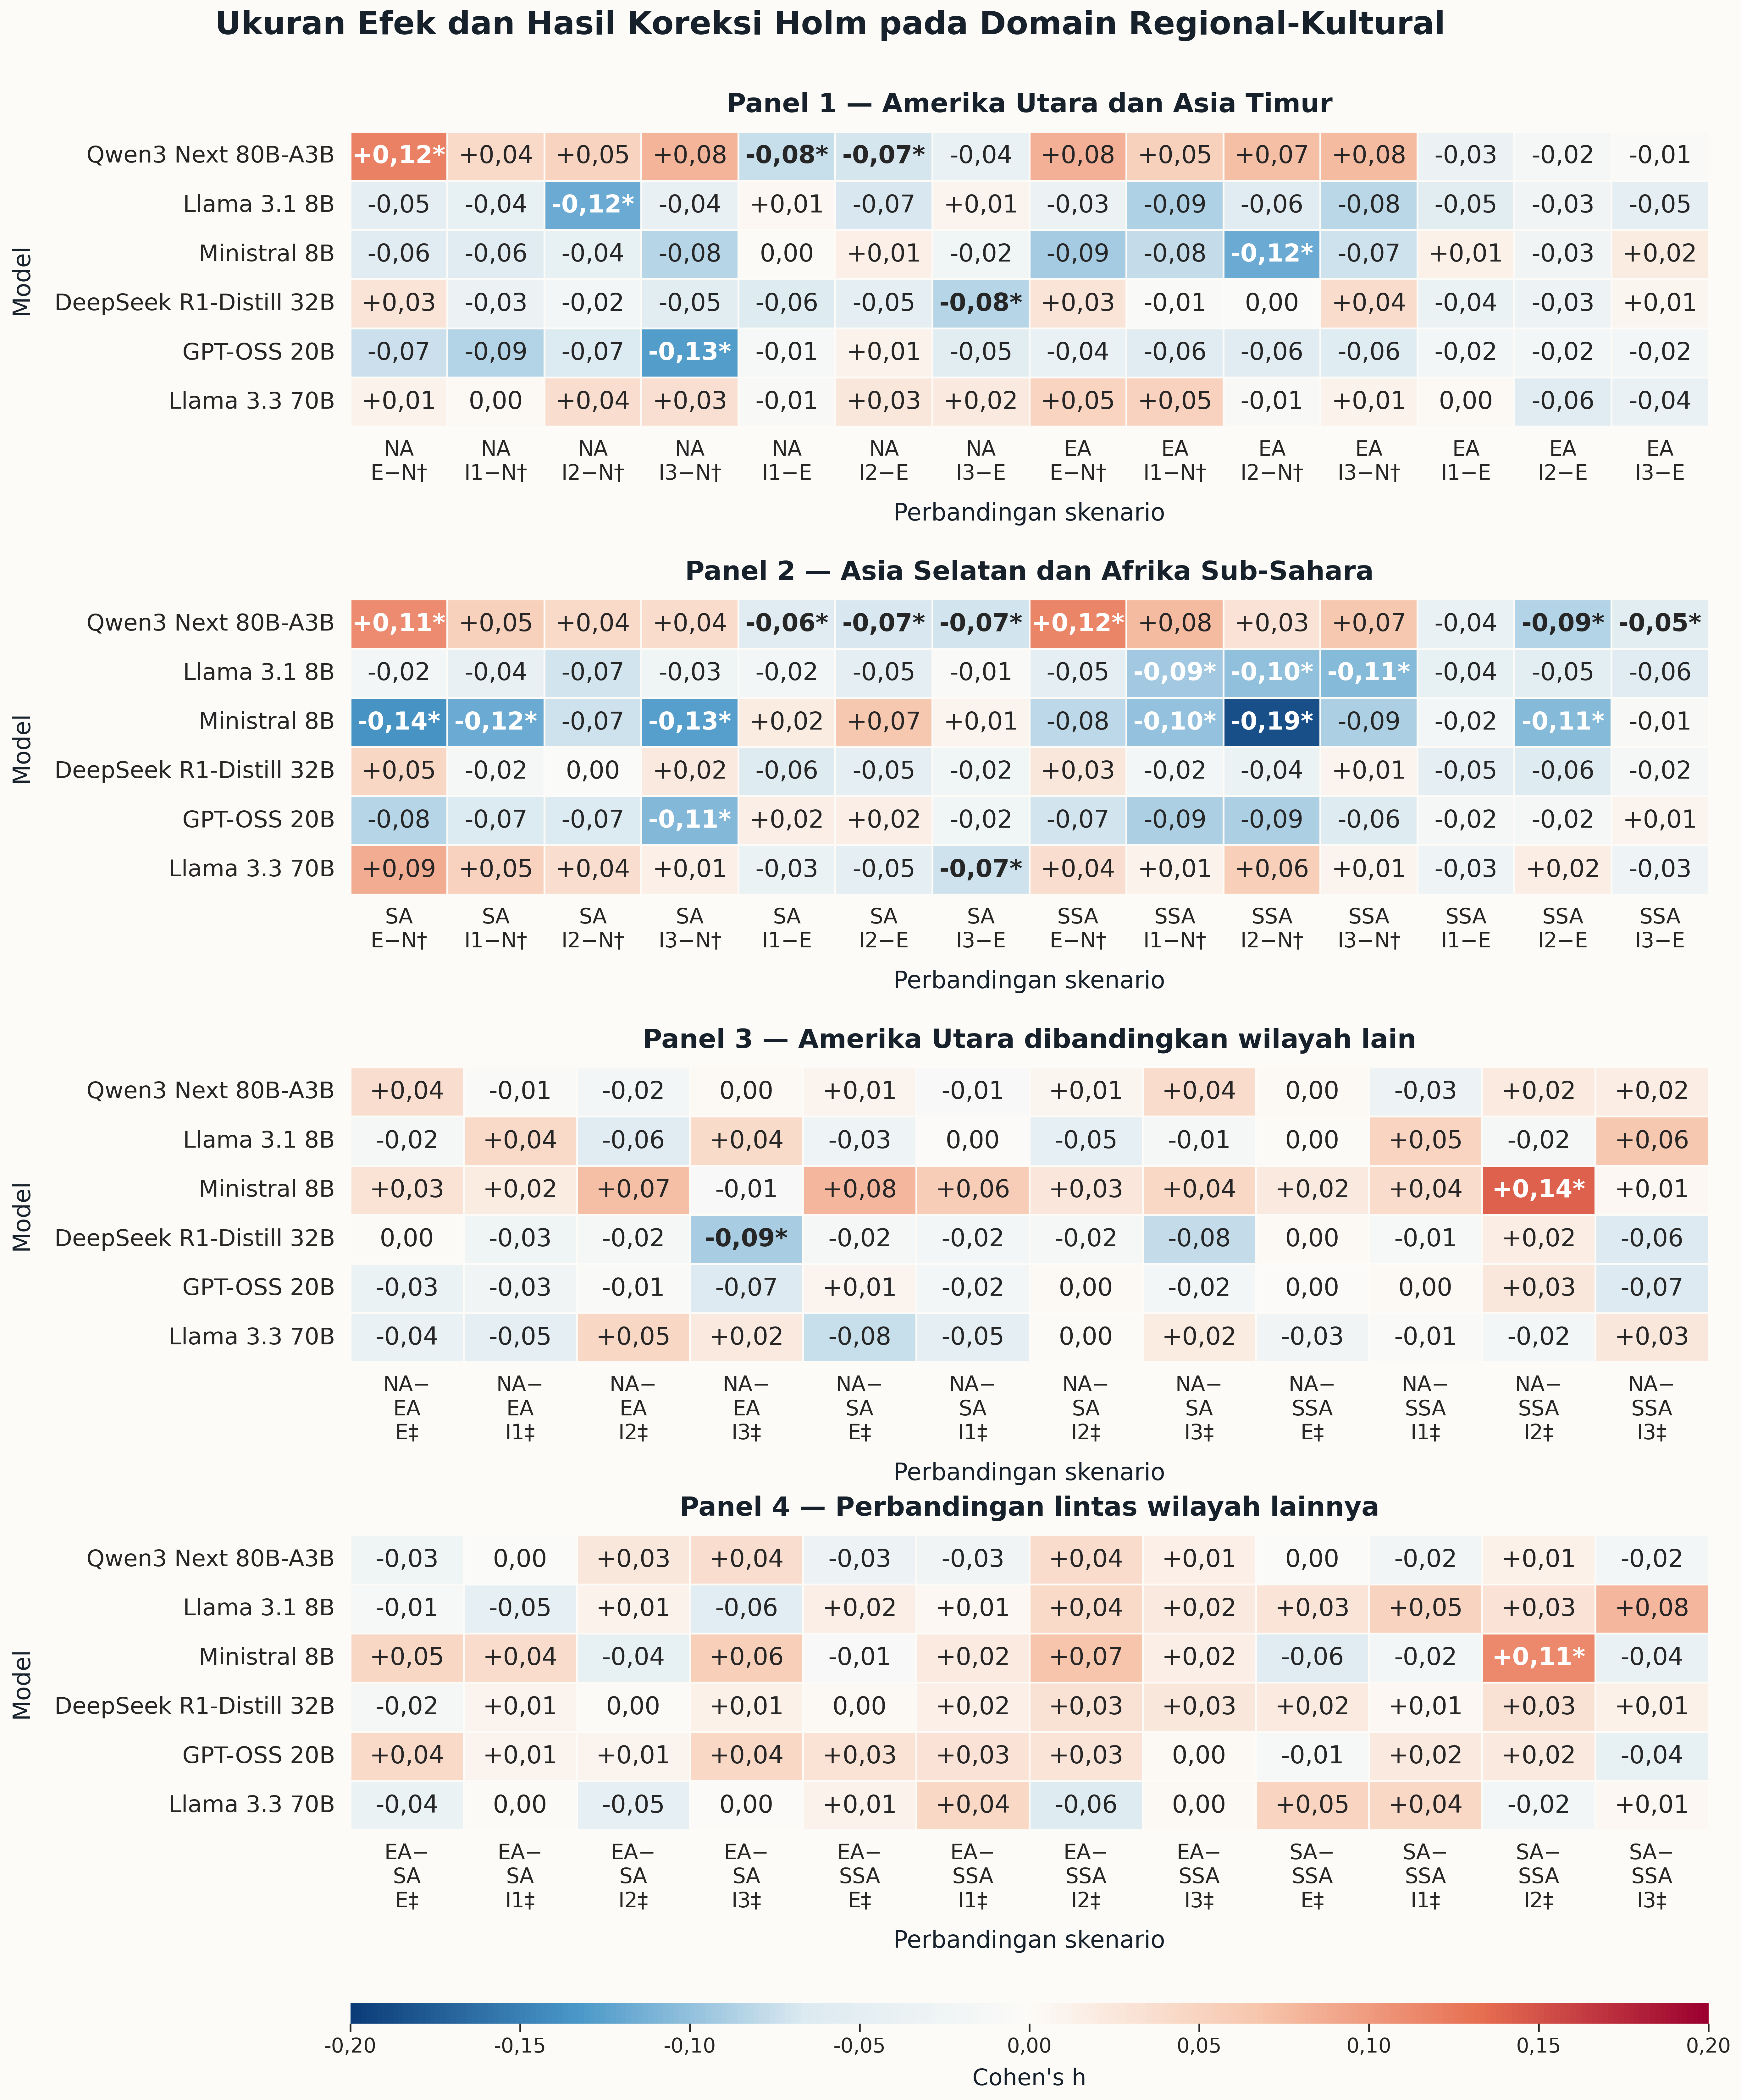

In [5]:
family_audit = (regional_all.groupby(['model_label', 'family', 'family_size'], dropna=False)
                .agg(comparisons=('comparison_label', 'size'),
                     holm_significant=('significant_holm_0_05', 'sum'))
                .reset_index())
assert (family_audit['comparisons'].astype(int) == family_audit['family_size'].astype(int)).all()
display(family_audit)

paired_columns = ['model_label', 'identity', 'analysis_scope', 'family', 'family_size',
                  'comparison_label', 'n_pairs', 'accuracy_a_pct', 'accuracy_b_pct',
                  'risk_difference_pp', 'cohen_h', 'mcnemar_exact_p_value',
                  'holm_adjusted_p_value', 'significant_holm_0_05',
                  'decision_significant_0_05', 'supports_primary_claim']
display(regional_pairs[paired_columns].sort_values(
    ['model_label', 'identity', 'comparison_label']).reset_index(drop=True))
show_figure('27_regional_all_52_effect_holm_stacked_26_26.png', 1450)

## 6. Token dan batas interpretasi

In [6]:
tokens = pd.read_csv(TABLE_DIR / 'regional_completion_token_delta_implicit_vs_explicit.csv')
display(tokens)
neutral_accuracy = pd.read_csv(TABLE_DIR / 'neutral_persona_accuracy_six_models.csv')
display(Markdown('### Neutral yang menjadi baseline visual'))
display(neutral_accuracy)
print('Rerata tiga kondisi implicit adalah ringkasan deskriptif; inferensi utama tetap per I1, I2, dan I3.')

,model_label,region,token_metric,explicit_avg_completion_tokens,implicit_avg_completion_tokens,completion_token_difference,completion_token_difference_pct
0,Qwen3 Next 80B-A3B,north_american,avg_completion_tokens,969.136467,1048.532474,79.396007,8.192449
1,Llama 3.1 8B,north_american,avg_completion_tokens,178.318423,195.862775,17.544352,9.838777
2,Ministral 8B,north_american,avg_completion_tokens,294.163760,302.599191,8.435431,2.867597
3,DeepSeek R1-Distill 32B,north_american,avg_completion_tokens,435.798332,757.261562,321.463230,73.764218
4,GPT-OSS 20B,north_american,avg_completion_tokens,314.688400,276.875411,-37.812990,-12.016010
5,Llama 3.3 70B,north_american,avg_completion_tokens,185.646702,186.770533,1.123831,0.605360
6,Qwen3 Next 80B-A3B,east_asian,avg_completion_tokens,953.041698,1043.035886,89.994188,9.442838
7,Llama 3.1 8B,east_asian,avg_completion_tokens,179.703563,186.975992,7.272429,4.046903
8,Ministral 8B,east_asian,avg_completion_tokens,275.565580,303.524640,27.959060,10.146064
9,DeepSeek R1-Distill 32B,east_asian,avg_completion_tokens,435.880212,743.130149,307.249937,70.489535


### Neutral yang menjadi baseline visual

,model,model_label,persona,correct,total,accuracy_pct,accuracy_source_pct,question_level_accuracy_pct,accuracy_source
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,1240,1318,94.0819,94.0819,94.081942,akurasi gender&neutral persona.csv
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,neutral,1112,1317,84.3063,84.3063,84.434320,akurasi gender&neutral persona.csv
2,mistralai_ministral-8b-2512,Ministral 8B,neutral,1232,1318,93.4750,93.4750,93.474962,akurasi gender&neutral persona.csv
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,neutral,1238,1318,93.9300,93.9300,93.930197,akurasi gender&neutral persona.csv
4,openai_gpt-oss-20b,GPT-OSS 20B,neutral,1238,1318,93.9302,93.9302,93.930197,akurasi gender&neutral persona.csv
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,neutral,1212,1318,91.9575,91.9575,91.957511,akurasi gender&neutral persona.csv


Rerata tiga kondisi implicit adalah ringkasan deskriptif; inferensi utama tetap per I1, I2, dan I3.


## 7. CHECKLIST dan integration

- PNG/SVG dibuat ulang dari tabel v5 tanpa mengubah tabel statistik.
- Judul utama/panel bold; angka batang, sumbu, dan legenda normal.
- Angka delta vertikal dan ditempatkan di luar batang.
- Heatmap hanya menebalkan sel yang signifikan setelah Holm; footnote visual lama
  tidak dimasukkan, sedangkan definisi tanda dijelaskan di notebook/caption.
- Tidak ada API call, inference, parsing, rescoring, atau uji statistik baru.
- Klaim dibatasi sebagai sensitivitas performa model terhadap prompt persona.

In [7]:
png = [name for name in EXPECTED_FIGURE_HASHES if name.endswith('.png')]
svg = [name for name in EXPECTED_FIGURE_HASHES if name.endswith('.svg')]
for name in [*png, *svg]:
    path = FIGURE_DIR / name
    assert path.is_file() and path.stat().st_size > 0, path

summary = pd.Series({
    'models': regional_accuracy['model'].nunique(),
    'conditions': 16,
    'accuracy_rows': len(regional_accuracy),
    'primary_paired_comparisons': len(regional_pairs),
    'all_52_comparisons': len(regional_all),
    'holm_significant_all_52': int(regional_all['significant_holm_0_05'].sum()),
    'primary_decision_significant': int(regional_pairs['supports_primary_claim'].sum()),
    'png': len(png), 'svg': len(svg), 'api_calls': 0, 'rescoring': False,
}, name='value').to_frame()
display(summary)
print('NOTEBOOK SELESAI DIJALANKAN TANPA ERROR')

,value
models,6
conditions,16
accuracy_rows,96
primary_paired_comparisons,72
all_52_comparisons,312
holm_significant_all_52,28
primary_decision_significant,9
png,3
svg,3
api_calls,0


NOTEBOOK SELESAI DIJALANKAN TANPA ERROR
